# 01. Análisis Exploratorio de Datos (EDA) - Predicción de Precios de Vehículos

## 1. Carga del Dataset y Verificación del Esquema

### Objetivo
Importar las librerías necesarias, configurar el entorno de visualización y cargar el dataset original (`carData.csv`) desde la ruta local reproducible `data/raw/`. 

Se verificará:
- Correcta lectura del archivo sin alterar el formato de origen.
- Dimensiones iniciales del conjunto de datos (filas y columnas).
- Inspección preliminar de los primeros registros y nombres de columnas.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración de visualización y estilo
plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.max_columns', None)

# Resolución reproducible de rutas relativas
PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "carData.csv"

# Carga de datos
df = pd.read_csv(DATA_PATH)

print(f"Ruta de lectura: {DATA_PATH}")
print(f"Dimensiones del dataset: {df.shape[0]} registros, {df.shape[1]} columnas\n")

df.head()

Ruta de lectura: C:\Users\lufeb\mlopsProyecto\data\raw\carData.csv
Dimensiones del dataset: 4340 registros, 8 columnas



,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


### Hallazgos y Conclusiones del Bloque 1
- **Dimensiones:** El dataset cuenta con 4.340 observaciones y 8 variables.
- **Variable Objetivo (*Target*):** `selling_price` (numérica continua, expresada en rupias indias - INR, moneda original del dataset indio CarDekho).
- **Variables Predictoras Iniciales:**
  - *Identificación/Categoría:* `name` (marca y modelo comercial del vehículo en formato compuesto).
  - *Numéricas temporales y de uso:* `year` (año de fabricación/modelo), `km_driven` (kilometraje recorrido acumulado).
  - *Categóricas de especificación:* `fuel` (tipo de combustible), `seller_type` (canal de venta: particular, concesionario o confiable), `transmission` (manual o automática), `owner` (número ordinal o historial de propietarios anteriores).

## 2. Inspección de Estructura, Tipos de Datos, Valores Nulos y Duplicados

### Objetivo
Evaluar la integridad y consistencia del dataset antes de cualquier transformación:
- Verificar los tipos de datos asignados por pandas a cada columna (`info`).
- Comprobar la presencia y porcentaje de valores nulos o faltantes (`isnull`).
- Detectar registros duplicados exactos en el conjunto de observaciones (`duplicated`).
- Evaluar la cardinalidad de valores únicos por cada variable predictora.

In [2]:
# 1. Resumen de tipos de datos y memoria
print("=== Estructura del DataFrame ===")
df.info()

# 2. Conteo de valores nulos por columna
print("\n=== Valores Faltantes(Nulos) ===")
missing_series = df.isnull().sum()
missing_pct = (missing_series / len(df)) * 100
missing_df = pd.DataFrame({'Nulos': missing_series, 'Porcentaje (%)': missing_pct})
print(missing_df)

# 3. Identificación de duplicados exactos
num_duplicates = df.duplicated().sum()
pct_duplicates = (num_duplicates / len(df)) * 100
print(f"\n=== Registros Duplicados ===")
print(f"Total filas duplicadas: {num_duplicates} ({pct_duplicates:.2f}%)")

# 4. Conteo de valores únicos por variable
print("\n=== Cardinalidad de Variables ===")
unique_counts = df.nunique()
print(unique_counts)

=== Estructura del DataFrame ===
<class 'pandas.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   name           4340 non-null   str  
 1   year           4340 non-null   int64
 2   selling_price  4340 non-null   int64
 3   km_driven      4340 non-null   int64
 4   fuel           4340 non-null   str  
 5   seller_type    4340 non-null   str  
 6   transmission   4340 non-null   str  
 7   owner          4340 non-null   str  
dtypes: int64(3), str(5)
memory usage: 515.2 KB

=== Valores Faltantes(Nulos) ===
               Nulos  Porcentaje (%)
name               0             0.0
year               0             0.0
selling_price      0             0.0
km_driven          0             0.0
fuel               0             0.0
seller_type        0             0.0
transmission       0             0.0
owner              0             0.0

=== Registros Duplicados ===
Total f

### Hallazgos y Conclusiones del Bloque 2
- **Valores Faltantes:** El dataset presenta 0 valores nulos en todas sus columnas; no se requiere imputación clásica de datos faltantes para esta versión cruda.
- **Registros Duplicados:** Existen 763 filas duplicadas exactas (~17.58% del dataset).
  - *Decisión técnica para MLOps:* En la fase de preprocesamiento se evaluará la eliminación de estos duplicados para evitar sobreajuste y sesgo de pesos hacia vehículos repetidos artificialmente en el entrenamiento.
- **Tipos de Datos:**
  - Numéricas: `year` (int64), `selling_price` (int64), `km_driven` (int64).
  - Categóricas/Texto: `name`, `fuel`, `seller_type`, `transmission`, `owner` (object).
- **Cardinalidad:**
  - `name` presenta 1.491 valores únicos, lo que representa una alta cardinalidad que no puede codificarse directamente con One-Hot Encoding sin generar dispersión masiva de dimensiones. Requiere extracción de la marca (*brand* o primer token).
  - `fuel`, `seller_type`, `transmission` y `owner` poseen baja cardinalidad (entre 2 y 5 categorías cada una), siendo ideales para codificación categórica en el pipeline.

## 3. Análisis Estadístico Descriptivo y Distribución Numérica

### Objetivo
Examinar la tendencia central, dispersión, asimetría y valores atípicos (outliers) de las variables cuantitativas:
- Calcular métricas de resumen estadístico (`describe`).
- Analizar la variable objetivo (`selling_price`) para identificar sesgos distributivos.
- Analizar el comportamiento del uso y antigüedad (`km_driven`, `year`).
- Generar histogramas y diagramas de caja (boxplots) para respaldar visualmente los hallazgos.

--- Resumen Estadístico de Variables Numéricas ---


,count,mean,std,min,25%,50%,75%,max,skew
year,4340.0,2013.090783,4.215344,1992.0,2011.00,2014.0,2016.0,2020.0,-0.833240
selling_price,4340.0,504127.311751,578548.736139,20000.0,208749.75,350000.0,600000.0,8900000.0,4.892021
km_driven,4340.0,66215.777419,46644.102194,1.0,35000.00,60000.0,90000.0,806599.0,2.669057


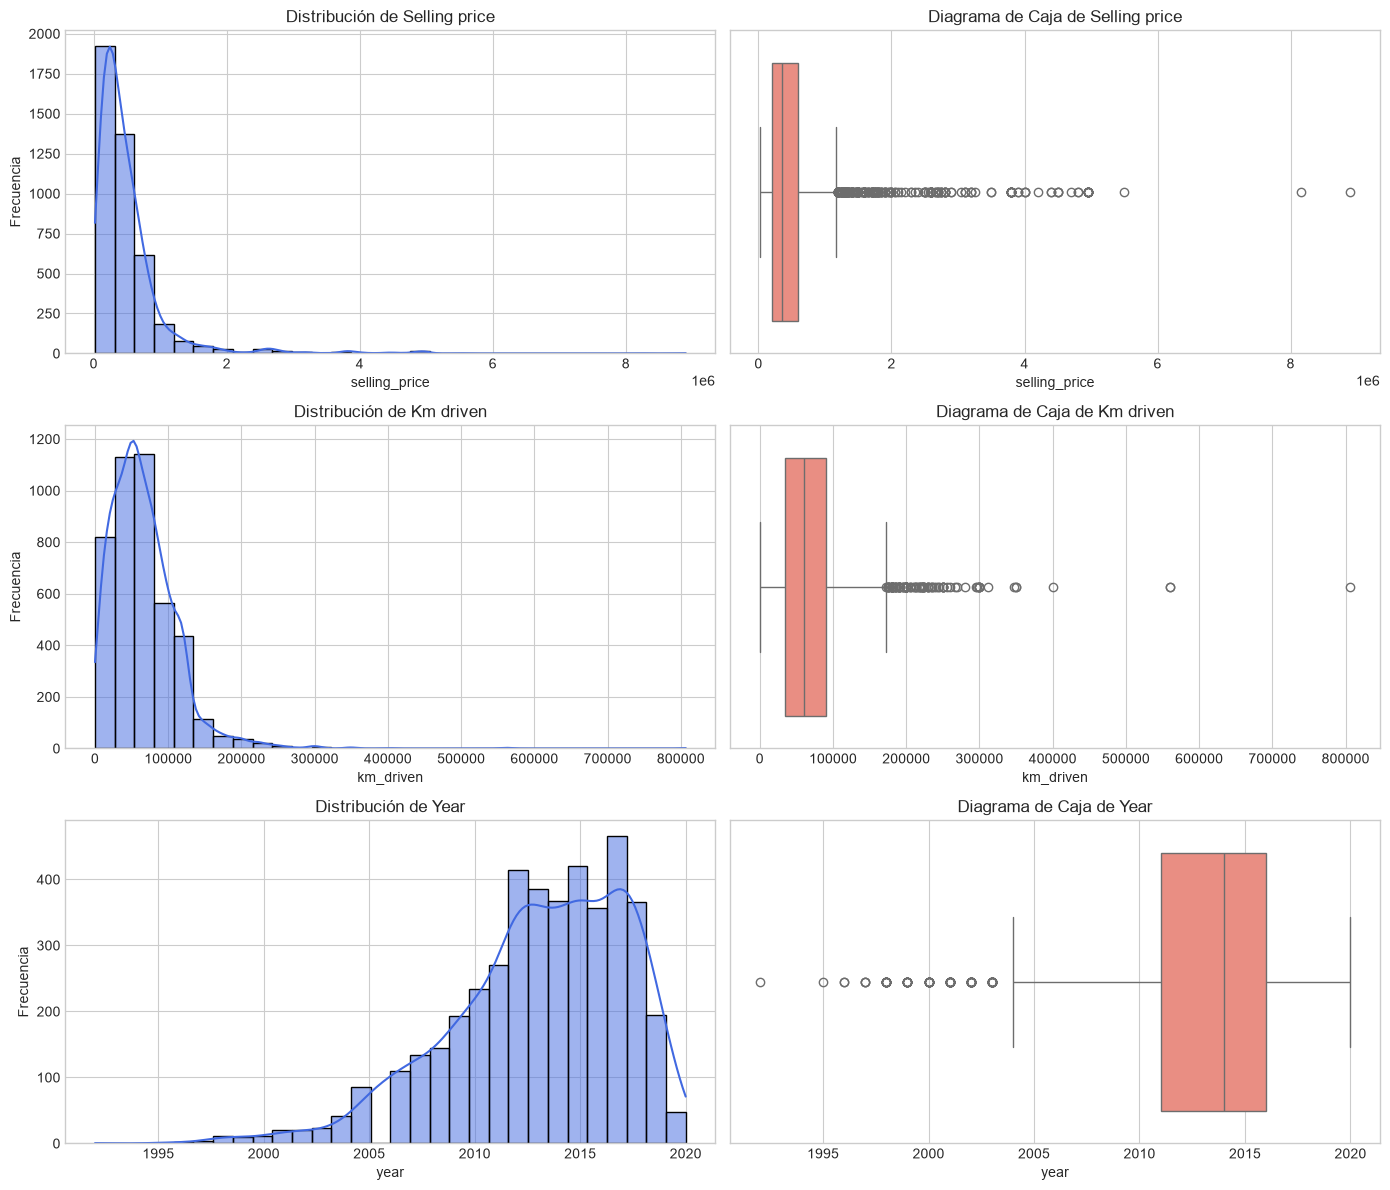

In [3]:
# 1. Resumen estadístico descriptivo
print("--- Resumen Estadístico de Variables Numéricas ---")
numeric_desc = df[["year", "selling_price", "km_driven"]].describe().T
numeric_desc["skew"] = df[["year", "selling_price", "km_driven"]].skew()
display(numeric_desc)

# 2. Visualización de distribuciones y detección de outliers
fig, axes = plt.subplots(3, 2, figsize=(14, 12))

features_num = ["selling_price", "km_driven", "year"]

for i, col in enumerate(features_num):
    # Histograma con KDE
    sns.histplot(df[col], kde=True, ax=axes[i, 0], color="royalblue", bins=30)
    axes[i, 0].set_title(f"Distribución de {col.replace('_', ' ').capitalize()}")
    axes[i, 0].set_xlabel(col)
    axes[i, 0].set_ylabel("Frecuencia")
    
    # Diagrama de caja (Boxplot)
    sns.boxplot(x=df[col], ax=axes[i, 1], color="salmon")
    axes[i, 1].set_title(f"Diagrama de Caja de {col.replace('_', ' ').capitalize()}")
    axes[i, 1].set_xlabel(col)

plt.tight_layout()
plt.show()

### Hallazgos y Conclusiones del Bloque 3
- **Variable objetivo (`selling_price`):**
  - Muestra un fuerte sesgo positivo (asimetría hacia la derecha con cola larga).
  - La gran mayoría de vehículos se concentra por debajo de 1.000.000 INR, pero existen unidades de lujo con precios que alcanzan hasta los 8.900.000 INR.
  - *Decisión técnica para MLOps:* Conviene evaluar una transformación logarítmica (`log1p`) sobre `selling_price` para estabilizar la varianza y mejorar el desempeño de modelos lineales o basados en gradiente.
- **Kilometraje recorrido (`km_driven`):**
  - Presenta una media cercana a los 66.000 km, con valores atípicos extremos que superan los 400.000 km e incluso un máximo de 806.599 km.
  - Al igual que el precio, exhibe asimetría positiva que requerirá escalado robusto o manejo de valores extremos.
- **Año de fabricación (`year`):**
  - Los modelos oscilan entre 1992 y 2020, con una concentración predominante entre 2012 y 2018 (mediana en 2014).
  - Presenta asimetría negativa leve debido a unos pocos vehículos muy antiguos (previos a 2005).
  - *Ingeniería de variables:* En etapas posteriores será más informativo calcular la antigüedad del vehículo (`antigüedad = año_actual - year`).

## 4. Análisis de Variables Categóricas y Relación Bivariada con el Precio

### Objetivo
Explorar la distribución de las variables cualitativas y medir su impacto directo sobre el precio de venta (`selling_price`):
- Evaluar frecuencias relativas y absolutas de `fuel`, `seller_type`, `transmission` y `owner`.
- Comparar las medianas y dispersión de precios para cada categoría mediante gráficos de caja.
- Identificar patrones de depreciación o sobreprecio según las características del vehículo.

--- Resumen de Variables Categóricas y Precios Medianos ---

Variable: Fuel


,Total,Mediana_Precio,Media_Precio
fuel,,,
Diesel,2153,500000.0,669094.252206
Electric,1,310000.0,310000.000000
Petrol,2123,269000.0,344840.137541
CNG,40,247500.0,277174.925000
LPG,23,180000.0,167826.043478



Variable: Seller type


,Total,Mediana_Precio,Media_Precio
seller_type,,,
Trustmark Dealer,102,750000.0,914950.980392
Dealer,994,495000.0,721822.890342
Individual,3244,300000.0,424505.419236



Variable: Transmission


,Total,Mediana_Precio,Media_Precio
transmission,,,
Automatic,448,950000.0,1.408154e+06
Manual,3892,325000.0,4.000667e+05



Variable: Owner


,Total,Mediana_Precio,Media_Precio
owner,,,
Test Drive Car,17,894999.0,954293.941176
First Owner,2832,450000.0,598636.969633
Second Owner,1106,250499.5,343891.088608
Third Owner,304,190000.0,269474.003289
Fourth & Above Owner,81,130000.0,173901.197531


C:\Users\lufeb\AppData\Local\Temp\ipykernel_30384\1089097234.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\lufeb\AppData\Local\Temp\ipykernel_30384\1089097234.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\lufeb\AppData\Local\Temp\ipykernel_30384\1089097234.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\lufeb\AppData\Local\Temp\ipykernel_30384\1089097234.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `h

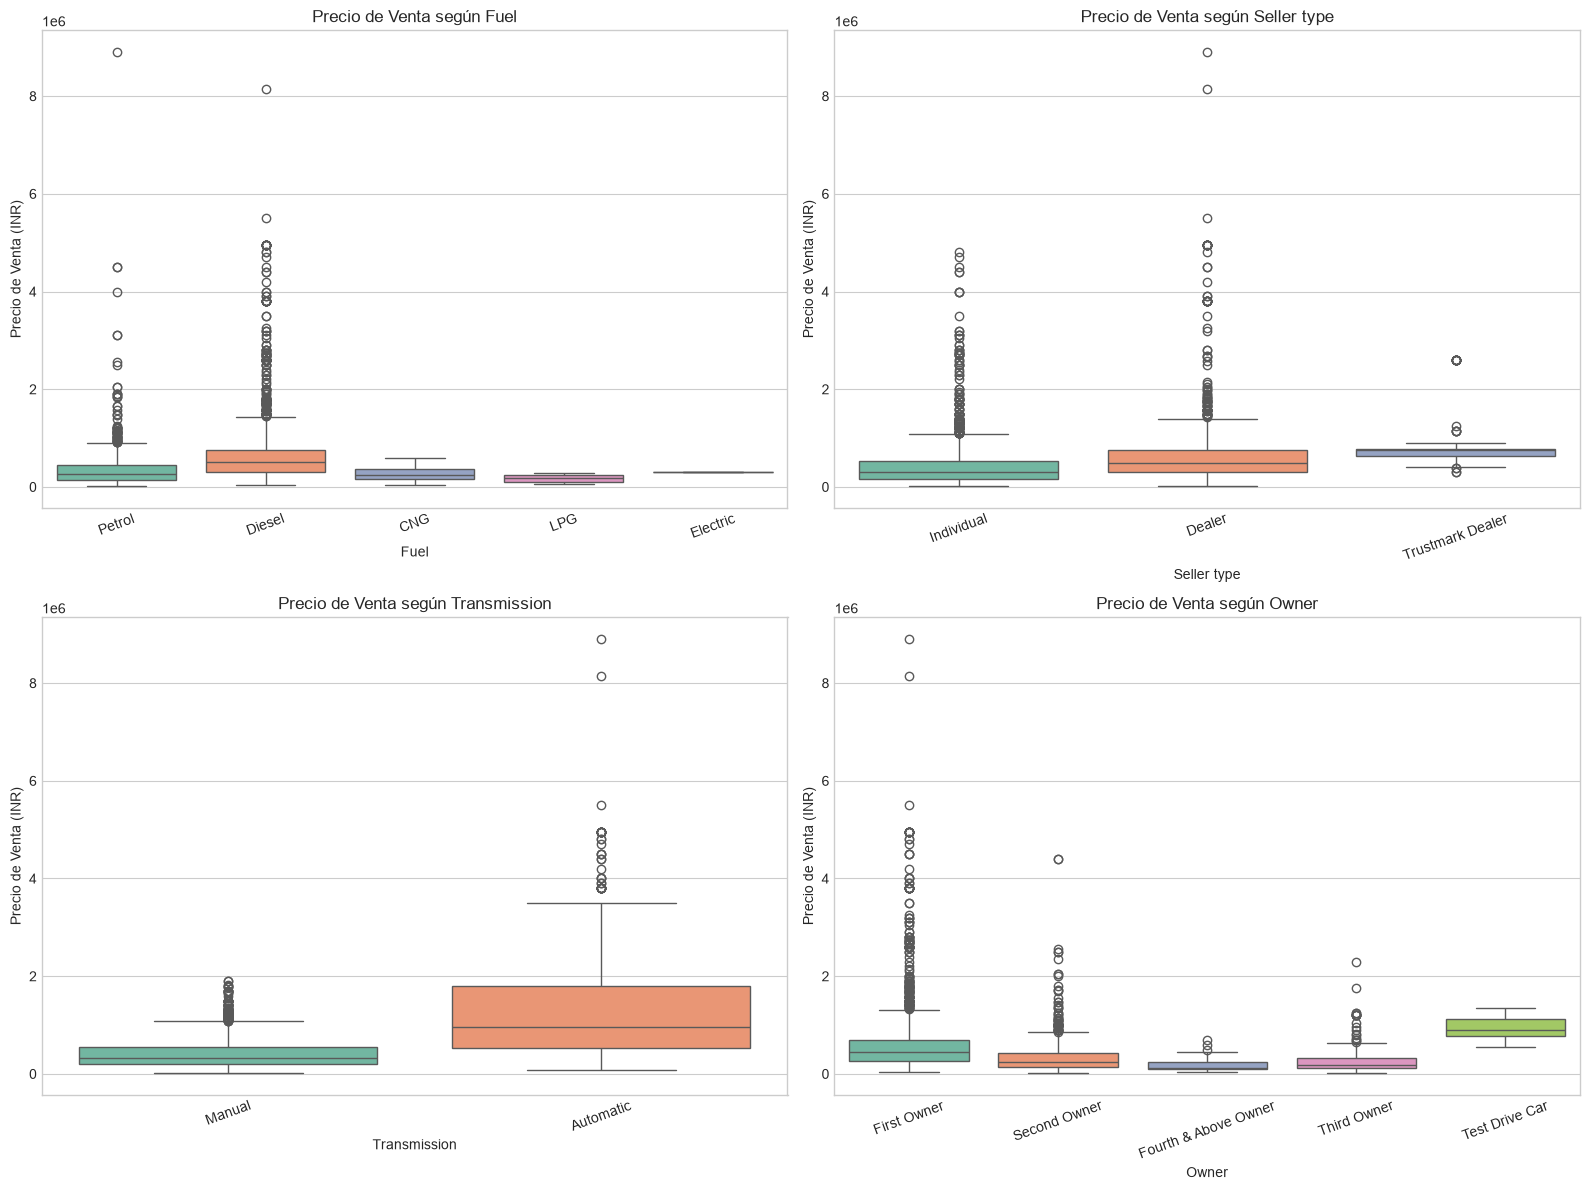

In [4]:
# 1. Definición de variables categóricas de baja cardinalidad
categorical_cols = ["fuel", "seller_type", "transmission", "owner"]

# 2. Conteo de frecuencias y cálculo de precio mediano por categoría
print("--- Resumen de Variables Categóricas y Precios Medianos ---")
for col in categorical_cols:
    summary_cat = df.groupby(col)["selling_price"].agg(
        Total="count",
        Mediana_Precio="median",
        Media_Precio="mean"
    ).sort_values(by="Mediana_Precio", ascending=False)
    
    print(f"\nVariable: {col.replace('_', ' ').capitalize()}")
    display(summary_cat)

# 3. Visualización bivariada: distribución de precios según categorías
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for i, col in enumerate(categorical_cols):
    sns.boxplot(
        data=df,
        x=col,
        y="selling_price",
        ax=axes[i],
        palette="Set2"
    )
    axes[i].set_title(f"Precio de Venta según {col.replace('_', ' ').capitalize()}")
    axes[i].set_xlabel(col.replace('_', ' ').capitalize())
    axes[i].set_ylabel("Precio de Venta (INR)")
    axes[i].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

### Hallazgos y Conclusiones del Bloque 4
- **Tipo de transmisión (`transmission`):**
  - Los vehículos automáticos tienen una mediana de precio significativamente superior frente a los manuales, concentrando además la mayor cantidad de valores de gama alta/lujo.
- **Tipo de combustible (`fuel`):**
  - Los autos diésel registran precios medianos más altos que los de gasolina, probablemente asociados a mayor cilindrada, torque y tamaño (SUVs).
  - Categorías alternativas como GNC (CNG), GLP (LPG) y eléctricos representan una fracción marginal del conjunto de datos.
- **Canal de venta (`seller_type`):**
  - Los concesionarios formales (`Dealer` y `Trustmark Dealer`) comercializan vehículos a precios medianos más altos que las transacciones entre particulares (`Individual`).
- **Historial de propietarios (`owner`):**
  - Se evidencia una clara tendencia de depreciación ordinal: `First Owner` presenta los precios más altos, disminuyendo progresivamente hacia `Second Owner`, `Third Owner` y `Fourth & Above Owner`.
  - *Decisión técnica para MLOps:* Esta variable presenta naturaleza ordinal y puede codificarse respetando su jerarquía numérica o mediante variables binarias (One-Hot Encoding).

## 5. Extracción de Marcas y Análisis de Alta Cardinalidad

### Objetivo
Resolver la alta dispersión de la columna `name` (1.491 valores únicos) mediante ingeniería de características preliminar:
- Extraer el fabricante o marca comercial (*brand*) a partir del primer término del nombre.
- Evaluar el número total de marcas presentes y su participación de mercado en el dataset.
- Analizar la dispersión de precios por marca para determinar si aporta poder predictivo relevante.
- Identificar marcas minoritarias candidatas a ser agrupadas en una categoría común (*Other*) en la etapa de preprocesamiento.

--- Distribución de Marcas en el Dataset ---
Total de marcas únicas identificadas: 29


,Cantidad,Porcentaje (%)
brand,,
Maruti,1280,29.493088
Hyundai,821,18.917051
Mahindra,365,8.410138
Tata,361,8.317972
Honda,252,5.806452
Ford,238,5.483871
Toyota,206,4.746544
Chevrolet,188,4.331797
Renault,146,3.364055


C:\Users\lufeb\AppData\Local\Temp\ipykernel_30384\2209028674.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


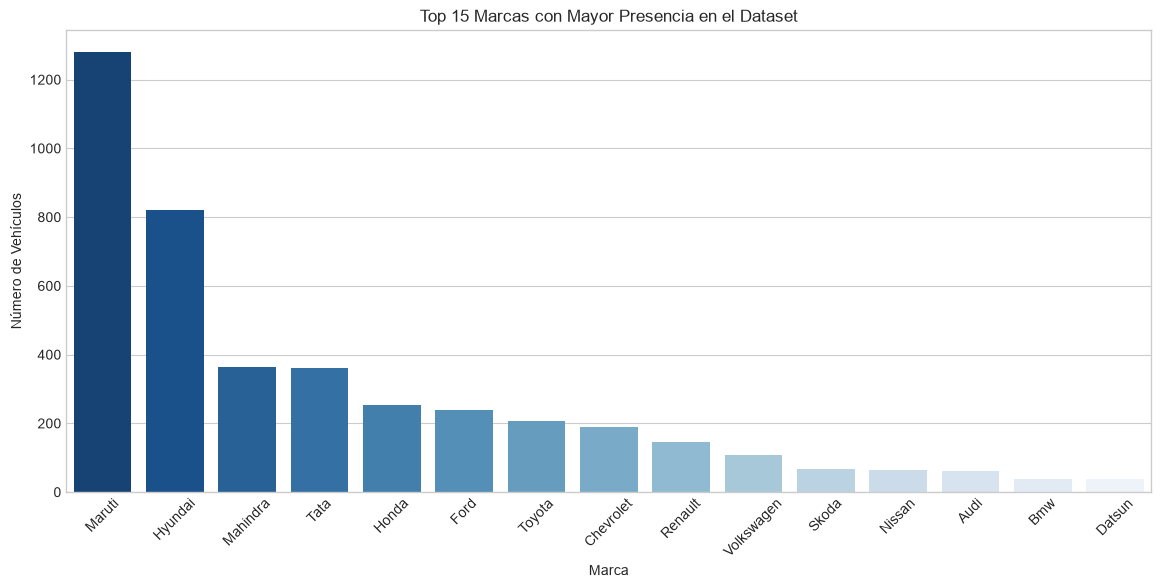

C:\Users\lufeb\AppData\Local\Temp\ipykernel_30384\2209028674.py:38: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


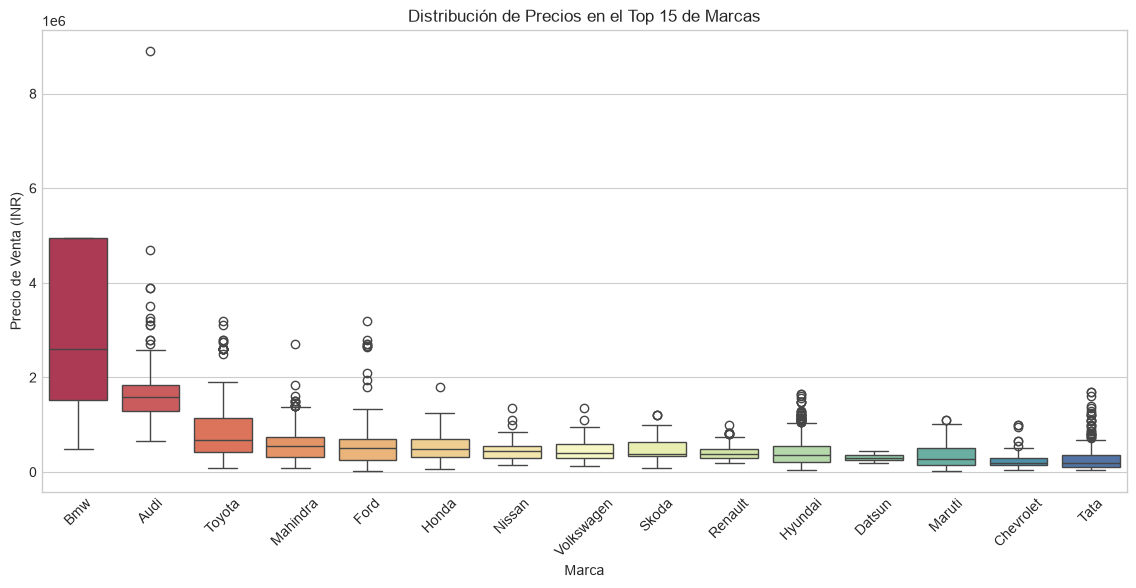

In [5]:
# 1. Extracción de la marca a partir del primer token de 'name'
df["brand"] = df["name"].apply(lambda x: x.split()[0].strip().title())

print("--- Distribución de Marcas en el Dataset ---")
brand_counts = df["brand"].value_counts()
brand_summary = pd.DataFrame({
    "Cantidad": brand_counts,
    "Porcentaje (%)": (brand_counts / len(df)) * 100
})

print(f"Total de marcas únicas identificadas: {df['brand'].nunique()}")
display(brand_summary.head(15))

# 2. Visualización: Top 15 marcas más frecuentes
plt.figure(figsize=(14, 6))
sns.barplot(
    x=brand_summary.head(15).index,
    y=brand_summary.head(15)["Cantidad"],
    palette="Blues_r"
)
plt.title("Top 15 Marcas con Mayor Presencia en el Dataset")
plt.xlabel("Marca")
plt.ylabel("Número de Vehículos")
plt.xticks(rotation=45)
plt.show()

# 3. Precio mediano por marca (Top 15 marcas)
top_brands = brand_summary.head(15).index
plt.figure(figsize=(14, 6))
df_top_brands = df[df["brand"].isin(top_brands)]
brand_price_order = (
    df_top_brands.groupby("brand")["selling_price"]
    .median()
    .sort_values(ascending=False)
    .index
)

sns.boxplot(
    data=df_top_brands,
    x="brand",
    y="selling_price",
    order=brand_price_order,
    palette="Spectral"
)
plt.title("Distribución de Precios en el Top 15 de Marcas")
plt.xlabel("Marca")
plt.ylabel("Precio de Venta (INR)")
plt.xticks(rotation=45)
plt.show()

### Hallazgos y Conclusiones del Bloque 5
- **Reducción de Cardinalidad:** Se redujo el espacio de la característica de 1.491 nombres compuestos a solo 29 marcas únicas.
- **Concentración de Mercado:**
  - Las tres marcas principales (*Maruti*, *Hyundai* y *Mahindra*) concentran más del 50% del total de vehículos ofertados.
  - El mercado refleja fielmente la estructura automotriz india, dominada ampliamente por fabricantes locales y asiáticos.
- **Segmentación por Rango de Precios:**
  - Marcas prémium/lujo como *BMW*, *Mercedes-Benz*, *Audi* y *Jaguar* registran medianas de precio notablemente superiores y explican la cola de valores extremos observada en el Bloque 3.
  - Marcas generalistas (*Maruti*, *Tata*, *Chevrolet*) mantienen distribuciones de precios compactas y accesibles.
- **Decisión Técnica para el Pipeline de MLOps:**
  - La variable `brand` es un predictor crítico para segmentar el valor base del vehículo.
  - Las marcas con muy baja frecuencia de aparición (por ejemplo, menos del 1% del total) deberán agruparse bajo una etiqueta común como `Other` durante el preprocesamiento para evitar sobreajuste en categorías raras.

## 6. Análisis de Correlación y Relaciones Multivariadas

### Objetivo
Evaluar el grado de asociación entre las variables cuantitativas y la variable objetivo:
- Calcular matrices de correlación de Pearson (asociación lineal) y Spearman (asociación monótona no lineal/robusta a valores extremos).
- Graficar mapas de calor (heatmaps) para identificar colinealidad o relaciones predictivas clave.
- Analizar diagramas de dispersión entre `selling_price`, `year` y `km_driven`, diferenciando por características clave como `transmission` o `fuel`.

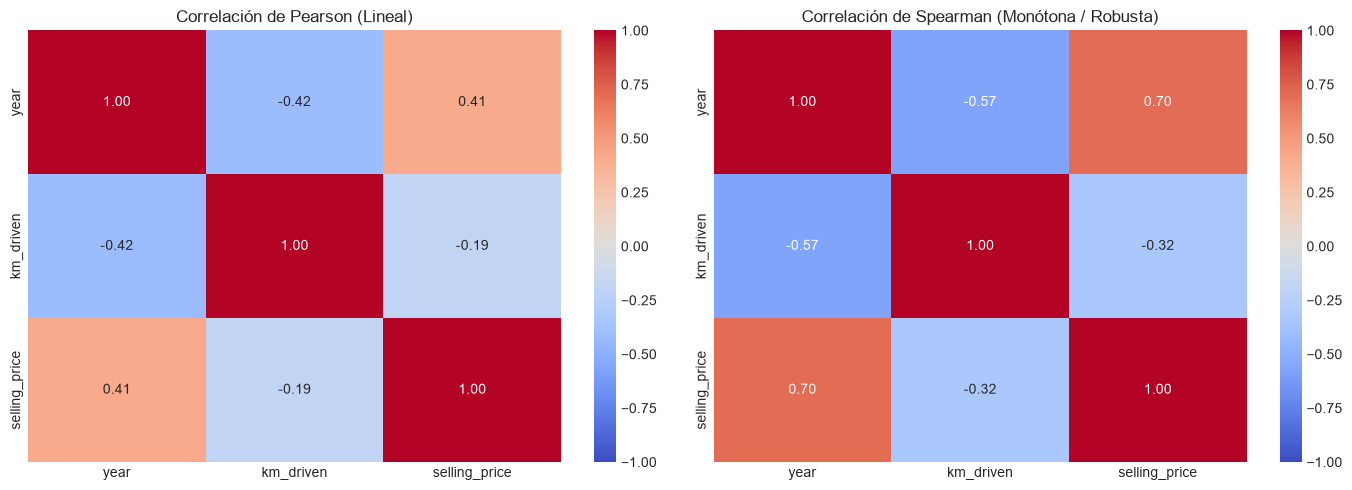

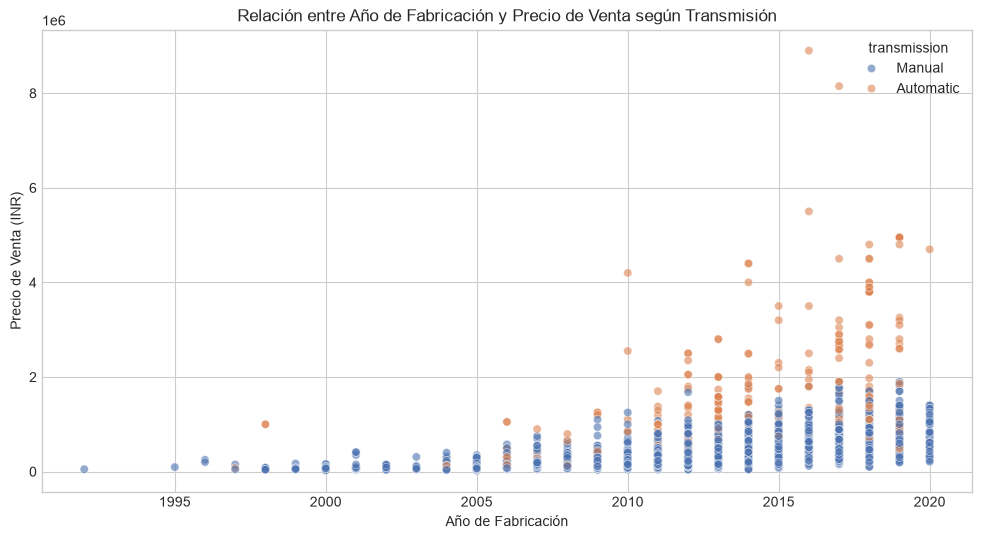

In [6]:
# 1. Matrices de correlación (Pearson y Spearman)
numeric_cols = ["year", "km_driven", "selling_price"]

corr_pearson = df[numeric_cols].corr(method="pearson")
corr_spearman = df[numeric_cols].corr(method="spearman")

# 2. Visualización: Mapas de calor comparativos
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(
    corr_pearson,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    cbar=True,
    ax=axes[0]
)
axes[0].set_title("Correlación de Pearson (Lineal)")

sns.heatmap(
    corr_spearman,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    cbar=True,
    ax=axes[1]
)
axes[1].set_title("Correlación de Spearman (Monótona / Robusta)")

plt.tight_layout()
plt.show()

# 3. Diagrama de dispersión multivariado: Año vs Precio según Transmisión
plt.figure(figsize=(12, 6))
sns.scatterplot(
    data=df,
    x="year",
    y="selling_price",
    hue="transmission",
    alpha=0.6,
    palette="deep"
)
plt.title("Relación entre Año de Fabricación y Precio de Venta según Transmisión")
plt.xlabel("Año de Fabricación")
plt.ylabel("Precio de Venta (INR)")
plt.show()

### Hallazgos y Conclusiones del Bloque 6
- **Correlación con el Precio:**
  - El año de fabricación (`year`) muestra una correlación positiva moderada-fuerte con `selling_price` (especialmente en Spearman, superando ~0.60), confirmando que a menor antigüedad, mayor valor comercial.
  - El kilometraje (`km_driven`) exhibe una correlación negativa moderada con el precio, coherente con el desgaste mecánico del activo.
- **Diferencia Pearson vs. Spearman:**
  - La correlación de Spearman es notablemente más fuerte que la de Pearson debido a la asimetría y presencia de valores extremos, lo que demuestra que la relación entre precio, año y kilometraje no es estrictamente lineal sino exponencial/curvilínea.
- **Interacción Multivariada:**
  - Los vehículos automáticos tienden a ubicarse en años más recientes (post-2012) y alcanzan precios sustancialmente mayores con la misma antigüedad.
  - La dispersión de precios crece exponencialmente en los modelos recientes, lo que refuerza la necesidad de transformar la variable objetivo (`log1p`) antes del modelado predictivo.

## 7. Síntesis Ejecutiva y Directrices para el Pipeline de MLOps

### Objetivo
Consolidar los hallazgos analíticos obtenidos a lo largo del EDA y traducirlos en directrices técnicas concretas para el diseño de los módulos de preprocesamiento, ingeniería de características y modelado predictivo.

### Directrices Técnicas para el Pipeline de MLOps

| Dimensión | Hallazgo en EDA | Directriz Técnica para el Pipeline (`src/features/`) |
| :--- | :--- | :--- |
| **Integridad de Datos** | 763 filas duplicadas exactas (~17.58%) y 0 valores nulos. | Eliminar duplicados exactos en la partición de entrenamiento para evitar fuga y sesgos. El pipeline mantendrá un paso de validación de esquema sin necesidad de imputación. |
| **Variable Objetivo (`selling_price`)** | Fuerte asimetría positiva (*skewness* = 4.89) con cola derecha de lujo. | Aplicar transformación logarítmica (`np.log1p`) a la variable dependiente antes del ajuste, y calcular la inversa (`np.expm1`) para las métricas de negocio (RMSE, MAE). |
| **Alta Cardinalidad (`name`)** | 1.491 valores únicos con nombres de versiones complejas. | Extraer el primer término como `brand`. Agrupar marcas con frecuencia inferior al 1% bajo la categoría común `Other`. |
| **Ingeniería Temporal (`year`)** | Los años oscilan entre 1992 y 2020 con mediana en 2014. | Transformar el año a una variable de antigüedad relativa (`vehicle_age = 2020 - year`). |
| **Variables Categóricas** | `transmission` binaria; `fuel`, `seller_type` nominales; `owner` ordinal. | Aplicar `OneHotEncoder` (con `drop='first'`) para nominales de baja cardinalidad y evaluar mapeo ordinal numérico para `owner`. |
| **Escalado Numérico (`km_driven`)** | Presencia de valores extremos de kilometraje (> 400.000 km, *skewness* = 2.67). | Utilizar `RobustScaler` o transformación logarítmica para evitar que outliers distorsionen modelos sensibles a escalas. |